# Backtest Report Explained
### QuantStack · *No hype. Just code.*

A six-part series on reading a backtest report: what every number means, how to code it, and how each one can mislead you. One notebook, one function at the end (`backtest_report`) that returns the whole report.

| Part | Topic | Section below |
|---|---|---|
| 1 | The settings that change every number | **Part 1** |
| 2 | Win rate, profit factor and expectancy | **Part 2** |
| 3 | Drawdown and the equity curve | **Part 3** |
| 4 | Returns and risk-adjusted ratios | **Part 4** |
| 5 | Is the result luck? | **Part 5** |
| 6 | Is it robust? + the final checklist | **Part 6** |


**How to use it.** Run top to bottom (`Restart & Run All`). Every metric is first computed on a **toy set of 10 trades whose answers you can check by hand**, with an `assert` that fails if the code disagrees with the hand calculation. Only then is it applied to larger data.

**Three kinds of data appear here, and each is labelled where it is used:**
1. **Toy data:** 10 trades, hand-checkable. For testing the code.
2. **Synthetic demo data:** randomly generated, seeded, clearly labelled `SYNTHETIC`. For demonstrating statistics (bootstrap, overfitting). It is **not** a real strategy result.
3. **Your own trade log:** the last section runs the same report on a trade log exported from the Breakout Strategy Framework notebook (Strategy 8). That is where the real numbers come from.

**Trade-log format** (the same columns the breakout notebook's engine produces): `entry_date`, `exit_date`, `pnl` (net of all costs, $), `risk_amount` ($ risked at entry). Optional: `symbol`. The equity curve is a Series indexed by date.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import dataclass, asdict
from itertools import groupby
from pathlib import Path
from scipy.stats import binom

PALETTE = {"equity": "#2E5EAA", "win": "#2E8B57", "loss": "#C1272D", "neutral": "#6B6B6B"}   # channel colours
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140); pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

---
# Part 1 — The settings that change every number

A backtest report has three parts: a **summary** (the headline numbers), a **trade log** (every trade), and an **equity curve** (account value over time). Every number in all three depends on the **settings** the backtest ran with. Read the settings *before* the numbers.

**The settings the breakout audit used** (from the Breakout Strategy Framework notebook, Sections 0 and 7–9):
- Starting balance **$10,000**, risk **1% per trade**, position size calculated from the stop distance
- Spread about **2 pips** in normal conditions, scaled **0.8× to 2.5×** by a volatility regime
- Slippage: **0.5 pip** base, scaled by regime and order size, plus a small random amount
- Commission **$2 per lot, charged on entry and exit**
- **One position at a time** across the whole portfolio (the Global Lock)
- Account stops taking trades at **1% of starting capital** (ruin floor)
- Each strategy ran on **the timeframe its own source used**

In [2]:
@dataclass(frozen=True)
class Settings:
    """Everything that changes the report. Teaching defaults mirror the breakout audit."""
    initial_capital: float = 10_000
    risk_pct: float = 0.01            # fraction of equity risked per trade
    spread_pips: float = 2.0          # paid once per round trip
    slippage_pips: float = 0.5        # paid on each side
    commission_per_lot: float = 2.0   # USD, charged on each side
    timeframe: str = "H1"
    window: str = "unspecified"
    fill_basis: str = "mid"           # price a fill is measured from: bar mid or next open
    max_open_positions: int = 1

def assumptions_table(s: Settings) -> pd.DataFrame:
    return pd.Series(asdict(s), name="value").to_frame()

assumptions_table(Settings(timeframe="H1", window="2006-10 to 2026-09"))     # the breakout audit's setup

,value
initial_capital,10000
risk_pct,0.0100
spread_pips,2.0000
slippage_pips,0.5000
commission_per_lot,2.0000
timeframe,H1
window,2006-10 to 2026-09
fill_basis,mid
max_open_positions,1


### 1.1 What costs do to a trade

Costs are fixed in *pips* but your risk is set by your *stop*. So the same cost is a small bite out of a wide stop and a huge one out of a tight stop. In **R units** (1R = the amount you risk on a trade):

`cost in R = round-trip cost in pips ÷ stop distance in pips`

Round-trip cost = spread (once) + slippage (both sides) + commission converted to pips (both sides). For a standard lot on a EURUSD-style pair, 1 pip ≈ $10.

,stop_pips,cost_R,cost_pct_of_stop
0,1.1000,3.0909,309.0909
1,5.0000,0.6800,68.0000
2,10.0000,0.3400,34.0000
3,15.5000,0.2194,21.9355
4,30.0000,0.1133,11.3333
5,100.0000,0.0340,3.4000
6,300.0000,0.0113,1.1333


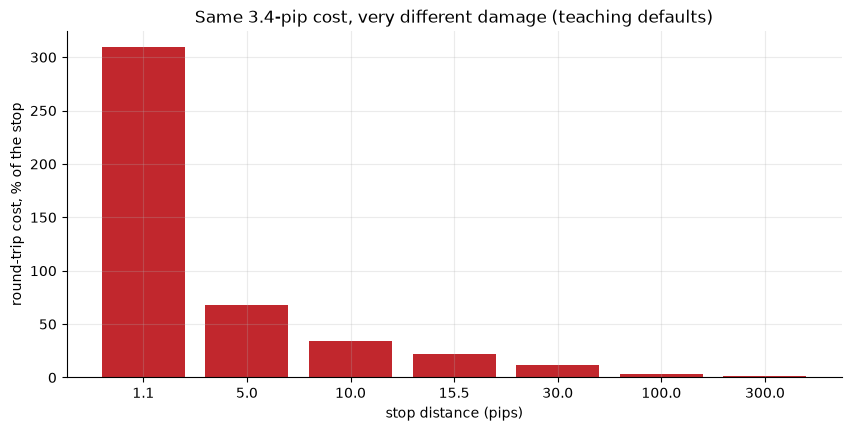

In [3]:
PIP_USD_PER_LOT = 10.0

def round_trip_cost_pips(s: Settings) -> float:
    return s.spread_pips + 2 * s.slippage_pips + 2 * s.commission_per_lot / PIP_USD_PER_LOT

def cost_in_R(stop_pips: float, s: Settings) -> float:
    return round_trip_cost_pips(s) / stop_pips

# --- hand check: 1.0 pip spread + 0.5 pip slippage x2 + $2 x2 commission (= 0.4 pip) = 2.4 pips = $24 per lot
s_hand = Settings(spread_pips=1.0, slippage_pips=0.5, commission_per_lot=2.0)
assert np.isclose(round_trip_cost_pips(s_hand), 2.4)
assert np.isclose(cost_in_R(10, s_hand), 0.24)          # 2.4 pips on a 10-pip stop = 0.24R

stops = np.array([1.1, 5, 10, 15.5, 30, 100, 300])
cost_table = pd.DataFrame({"stop_pips": stops, "cost_R": [cost_in_R(x, Settings()) for x in stops]})
cost_table["cost_pct_of_stop"] = cost_table.cost_R * 100
display(cost_table)

fig, ax = plt.subplots()
ax.bar([str(x) for x in stops], cost_table.cost_pct_of_stop, color=PALETTE["loss"])
ax.set(xlabel="stop distance (pips)", ylabel="round-trip cost, % of the stop",
       title=f"Same {round_trip_cost_pips(Settings()):.1f}-pip cost, very different damage (teaching defaults)")
plt.show()

**Receipt from the breakout audit (Section 9a-ii):** Strategy 5 had a *median stop of 1.1 pips* against an entry cost of about *1.5 pips* (entry side only, so a lower bound on the round trip). 63% of its stops were smaller than the entry cost alone. Strategy 1's median stop was 15.5 pips against about 1.7 pips of entry cost.

### 1.2 Position size from the stop

Fixed-fractional sizing: risk a fixed % of equity, so the **stop distance sets the size**.

`units = equity × risk% ÷ (stop in pips × value of 1 pip per unit)`

In [4]:
def position_units(equity, risk_pct, stop_pips, pip_value_per_unit=0.0001):
    return equity * risk_pct / (stop_pips * pip_value_per_unit)

# hand check: $10,000 x 1% = $100 at risk; 20-pip stop; $0.0001 per pip per unit  ->  50,000 units (0.5 lot)
assert np.isclose(position_units(10_000, 0.01, 20), 50_000)
# a wider stop means a smaller position, a tighter stop a bigger one
print({stop: position_units(10_000, 0.01, stop) for stop in (5, 20, 100)})

{5: 200000.0, 20: 50000.0, 100: 10000.0}


### 1.3 Data quality: check the candles before you trust the report

The same four checks the breakout audit ran on every pair: duplicate timestamps, missing values, impossible candles (high below low), and unexpected gaps on weekdays. Below, the checker is tested on a small **deliberately corrupted synthetic frame** (one fault of each kind injected), so you can see it catch them.

In [5]:
def data_quality(df: pd.DataFrame, bar: str = "1h") -> dict:
    idx = df.index.to_series()
    return {"duplicate_timestamps": int(df.index.duplicated().sum()),
            "null_ohlc": int(df[["open", "high", "low", "close"]].isna().sum().sum()),
            "high_below_low": int((df.high < df.low).sum()),
            "weekday_gaps_gt_3_bars": int(((idx.diff() > 3 * pd.Timedelta(bar)) & (idx.dt.dayofweek < 5)).sum())}

# SYNTHETIC frame with one injected fault of each kind
rng = np.random.default_rng(5)
close = 1.10 + np.cumsum(rng.normal(0, 0.0005, 48))
bars = pd.DataFrame({"open": close - 0.0001, "high": close + 0.0004, "low": close - 0.0004, "close": close},
                    index=pd.date_range("2024-01-02", periods=48, freq="h"))       # a Tuesday-Wednesday
bars = pd.concat([bars, bars.iloc[[5]]]).sort_index()                              # 1 duplicate timestamp
bars.iloc[10, bars.columns.get_loc("close")] = np.nan                              # 1 missing value
bars.iloc[20, [bars.columns.get_loc("high"), bars.columns.get_loc("low")]] = bars.iloc[20][["low", "high"]].to_numpy()  # high < low
bars = bars.drop(bars.index[31:40])                                                # 9 missing bars -> 1 gap

print(data_quality(bars))
assert data_quality(bars) == {"duplicate_timestamps": 1, "null_ohlc": 1, "high_below_low": 1, "weekday_gaps_gt_3_bars": 1}

{'duplicate_timestamps': 1, 'null_ohlc': 1, 'high_below_low': 1, 'weekday_gaps_gt_3_bars': 1}


---
# Part 2 — Win rate, profit factor and expectancy

## The toy trade set

Ten trades, $100 risked on each (1R = $100), net of all costs. **Every number below can be verified by hand.**

| Trade | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| P&L ($) | +150 | −100 | −100 | +200 | −100 | +100 | −100 | −100 | +250 | −100 |

**By hand:**
- Wins: 150, 200, 100, 250 → **4 of 10 = 40%** win rate; gross profit = **$700**
- Losses: six × $100 → gross loss = **$600**
- Average win = 700 ÷ 4 = **$175**; average loss = 600 ÷ 6 = **$100**; payoff ratio = 175 ÷ 100 = **1.75**
- Profit factor = 700 ÷ 600 = **1.1667**
- Expectancy = 0.40 × 175 − 0.60 × 100 = **$10 per trade = 0.10R**
- Breakeven win rate at this payoff = 100 ÷ (175 + 100) = **36.36%**

In [6]:
toy_pnl = [150, -100, -100, 200, -100, 100, -100, -100, 250, -100]
days = pd.bdate_range("2024-01-01", periods=30)                    # business days; each trade is open 2 days, then a 1-day gap
toy = pd.DataFrame({"symbol": ["EURUSD", "GBPUSD"] * 5, "entry_date": days[0::3], "exit_date": days[2::3],
                    "pnl": toy_pnl, "risk_amount": 100.0})
toy

,symbol,entry_date,exit_date,pnl,risk_amount
0,EURUSD,2024-01-01,2024-01-03,150,100.0000
1,GBPUSD,2024-01-04,2024-01-08,-100,100.0000
2,EURUSD,2024-01-09,2024-01-11,-100,100.0000
3,GBPUSD,2024-01-12,2024-01-16,200,100.0000
4,EURUSD,2024-01-17,2024-01-19,-100,100.0000
5,GBPUSD,2024-01-22,2024-01-24,100,100.0000
6,EURUSD,2024-01-25,2024-01-29,-100,100.0000
7,GBPUSD,2024-01-30,2024-02-01,-100,100.0000
8,EURUSD,2024-02-02,2024-02-06,250,100.0000
9,GBPUSD,2024-02-07,2024-02-09,-100,100.0000


In [7]:
def trade_metrics(t: pd.DataFrame) -> dict:
    pnl = t.pnl; wins, losses = pnl[pnl > 0], pnl[pnl <= 0]            # a breakeven trade counts as a loss, as in the breakout notebook
    n, win_rate = len(t), len(wins) / len(t)
    avg_win = wins.mean() if len(wins) else 0.0
    avg_loss = -losses.mean() if len(losses) else 0.0                  # stored as a positive number
    return {"trade_count": n, "win_rate": win_rate, "avg_win": avg_win, "avg_loss": avg_loss,
            "payoff_ratio": avg_win / avg_loss if avg_loss else np.inf,
            "profit_factor": wins.sum() / -losses.sum() if len(losses) and losses.sum() else np.inf,
            "expectancy_usd": pnl.mean(), "expectancy_R": (pnl / t.risk_amount).mean(),
            "breakeven_win_rate": avg_loss / (avg_win + avg_loss) if avg_win + avg_loss else np.nan,
            "largest_win": pnl.max(), "largest_loss": pnl.min(),
            "avg_duration": (t.exit_date - t.entry_date).mean()}

tm = trade_metrics(toy)
assert tm["trade_count"] == 10 and np.isclose(tm["win_rate"], 0.40)
assert np.isclose(tm["avg_win"], 175) and np.isclose(tm["avg_loss"], 100) and np.isclose(tm["payoff_ratio"], 1.75)
assert np.isclose(tm["profit_factor"], 700 / 600)
assert np.isclose(tm["expectancy_usd"], 10) and np.isclose(tm["expectancy_R"], 0.10)
assert np.isclose(tm["breakeven_win_rate"], 100 / 275)
assert tm["largest_win"] == 250 and tm["largest_loss"] == -100
# expectancy two ways: mean P&L == win_rate x avg_win - loss_rate x avg_loss
assert np.isclose(tm["expectancy_usd"], tm["win_rate"] * tm["avg_win"] - (1 - tm["win_rate"]) * tm["avg_loss"])
pd.Series(tm, name="toy trades").to_frame()

,toy trades
trade_count,10
win_rate,0.4000
avg_win,175.0000
avg_loss,100.0000
payoff_ratio,1.7500
profit_factor,1.1667
expectancy_usd,10.0000
expectancy_R,0.1000
breakeven_win_rate,0.3636
largest_win,250


### 2.1 Breakeven win rate: before and after costs

With payoff ratio `b` (average win ÷ average loss), you break even at a win rate of `1 ÷ (1 + b)`. Costs shift both sides: a win is worth `W − c`, a loss costs `L + c` (in R). Setting expectancy to zero gives:

`breakeven win rate = (L + c) ÷ (W + L)`

A 1:1 strategy (W = L = 1R) with a cost of 0.24R needs **62%** wins, not 50%.

In [8]:
def breakeven_win_rate(win_R: float, loss_R: float, cost_R: float = 0.0) -> float:
    return (loss_R + cost_R) / (win_R + loss_R)

assert np.isclose(breakeven_win_rate(1, 1), 0.50)
assert np.isclose(breakeven_win_rate(1, 1, cost_R=0.24), 0.62)        # the 10-pip-stop example from Part 1
assert np.isclose(breakeven_win_rate(1.75, 1), 1 / 2.75)              # matches the toy set's 36.36%
pd.DataFrame({"cost_R": c, "breakeven_win_rate_1to1": breakeven_win_rate(1, 1, c)} for c in (0, 0.05, 0.1, 0.24, 0.5))

,cost_R,breakeven_win_rate_1to1
0,0.0000,0.5000
1,0.0500,0.5250
2,0.1000,0.5500
3,0.2400,0.6200
4,0.5000,0.7500


### 2.2 The win-rate trap

A high win rate says nothing without the payoff ratio. A strategy that wins **80%** of the time with an average win of $25 and an average loss of $100 has an expectancy of exactly **zero** before costs, and a negative one after.

In [9]:
win_rate, avg_win, avg_loss, cost_per_trade = 0.80, 25, 100, 2
exp_gross = win_rate * avg_win - (1 - win_rate) * avg_loss
assert np.isclose(exp_gross, 0.0) and np.isclose(breakeven_win_rate(avg_win, avg_loss), 0.80)
print(f"80% win rate | expectancy before costs: ${exp_gross:.2f} | after ${cost_per_trade} cost per trade: ${exp_gross - cost_per_trade:.2f}")

80% win rate | expectancy before costs: $0.00 | after $2 cost per trade: $-2.00


---
# Part 3 — Drawdown and the equity curve

**Drawdown** = how far equity has fallen from its previous peak: `(peak − equity) ÷ peak`.
Two curves can be used and they give different answers:
- **Closed-trade equity**: updated only when a trade closes. Hides the pain inside open trades.
- **Mark-to-market (MTM) equity**: includes the unrealised profit/loss of open positions. This is what your account balance showed you while you sat through it.

### The toy equity curve
The same 10 trades, 30 business days. Each trade is open 2 days; on the middle day the open trade shows an unrealised P&L. Trade 4 finishes +$200 but sits $120 under water first.

| Trade | 1 | 2 | 3 | **4** | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| Unrealised mid-trade ($) | +50 | −60 | −80 | **−120** | −90 | +40 | −70 | −100 | +120 | −50 |

**By hand:**
- Closed equity: 10,000 → 10,150 → 10,050 → 9,950 → 10,150 → 10,050 → 10,150 → 10,050 → 9,950 → 10,200 → 10,100. Worst fall from a peak: 10,150 → 9,950 = **$200 = 1.970%**
- MTM: trade 4's mid-point is 9,950 − 120 = 9,830. Worst fall: 10,150 → 9,830 = **$320 = 3.153%**
- Longest losing streak: **2** (trades 2–3 and 7–8); longest winning streak: **1**
- Longest time under water: **7 bars** (days 4–10)
- Exposure: each trade is open 2 of every 3 days → 20 of 30 days = **66.7%**

In [10]:
mid = [50, -60, -80, -120, -90, 40, -70, -100, 120, -50]            # unrealised P&L on each trade's middle day
closed = 10_000 + np.r_[0, np.cumsum(toy_pnl)]
toy_equity = np.empty(30)
for i, (u, p) in enumerate(zip(mid, toy_pnl)):
    toy_equity[3*i: 3*i + 3] = [closed[i], closed[i] + u, closed[i] + p]
toy_equity = pd.Series(toy_equity, index=days, name="equity")

def closed_equity(trades: pd.DataFrame, ic: float) -> np.ndarray:
    return np.r_[ic, ic + trades.pnl.cumsum().to_numpy()]

def drawdown_stats(equity) -> dict:
    eq = np.asarray(equity, float); peak = np.maximum.accumulate(eq)
    runs = [len(list(g)) for under, g in groupby(eq < peak) if under]
    return {"max_dd_pct": ((peak - eq) / peak).max(), "max_dd_usd": (peak - eq).max(),
            "longest_underwater_bars": max(runs, default=0)}

def max_streak(pnl, wins: bool) -> int:
    return max((len(list(g)) for hit, g in groupby((np.asarray(pnl) > 0) == wins) if hit), default=0)

def exposure(trades: pd.DataFrame, index: pd.DatetimeIndex) -> float:
    in_trade = np.zeros(len(index), bool)
    for e, x in zip(trades.entry_date, trades.exit_date):
        in_trade |= (index >= e) & (index < x)
    return in_trade.mean()

def recovery_factor(net_profit: float, max_dd_usd: float) -> float:
    return net_profit / max_dd_usd if max_dd_usd else np.inf

dd_closed = drawdown_stats(closed_equity(toy, 10_000)); dd_mtm = drawdown_stats(toy_equity)
assert np.isclose(dd_closed["max_dd_usd"], 200) and np.isclose(dd_closed["max_dd_pct"], 200 / 10_150)
assert np.isclose(dd_mtm["max_dd_usd"], 320) and np.isclose(dd_mtm["max_dd_pct"], 320 / 10_150)
assert dd_mtm["longest_underwater_bars"] == 7
assert max_streak(toy_pnl, wins=False) == 2 and max_streak(toy_pnl, wins=True) == 1
assert np.isclose(exposure(toy, toy_equity.index), 20 / 30)
assert np.isclose(recovery_factor(sum(toy_pnl), dd_mtm["max_dd_usd"]), 100 / 320)

pd.DataFrame({"closed-trade": dd_closed, "mark-to-market": dd_mtm})

,closed-trade,mark-to-market
max_dd_pct,0.0197,0.0315
max_dd_usd,200.0000,320.0000
longest_underwater_bars,2.0000,7.0000


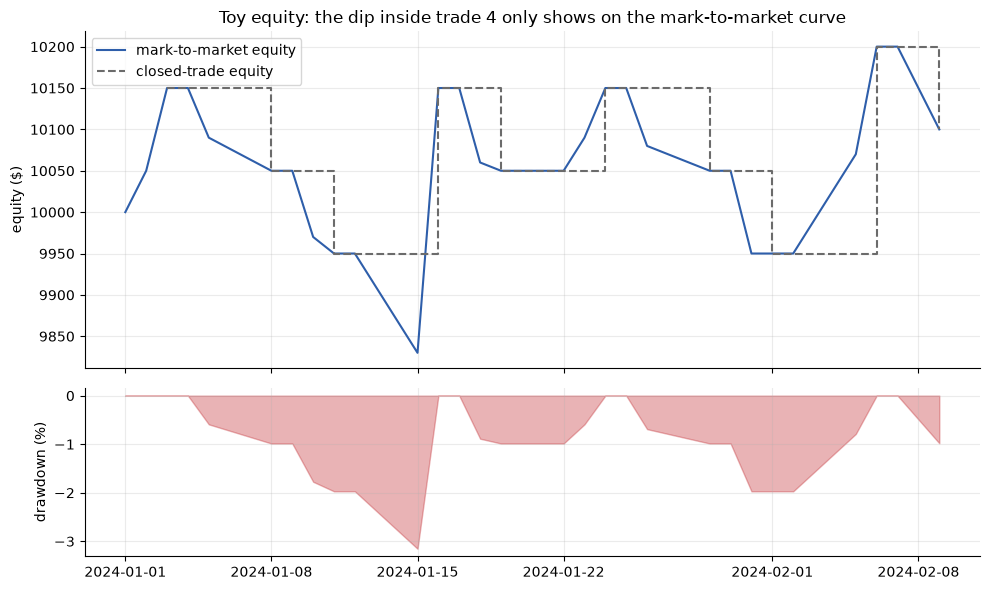

In [11]:
def plot_equity_with_drawdown(equity: pd.Series, closed_points: pd.Series | None = None, title=""):
    peak = equity.cummax(); dd = (equity - peak) / peak * 100
    fig, (a, b) = plt.subplots(2, 1, sharex=True, figsize=(10, 6), gridspec_kw={"height_ratios": [2, 1]})
    a.plot(equity.index, equity, color=PALETTE["equity"], label="mark-to-market equity")
    if closed_points is not None:
        a.step(closed_points.index, closed_points, where="post", color=PALETTE["neutral"], ls="--", label="closed-trade equity")
    a.set(ylabel="equity ($)", title=title); a.legend()
    b.fill_between(equity.index, dd, 0, color=PALETTE["loss"], alpha=0.35); b.set(ylabel="drawdown (%)")
    plt.tight_layout(); plt.show()

closed_pts = pd.Series(closed[1:], index=toy.exit_date)
plot_equity_with_drawdown(toy_equity, closed_pts, "Toy equity: the dip inside trade 4 only shows on the mark-to-market curve")

### 3.0 Drawdown detail: when it happened, how long it lasted, and whether it is over

Maximum drawdown is one number. Three more questions complete it:
- **When?** The date of the trough, and of the peak it fell from.
- **How long?** Time under water in **calendar days** (bars are fine for code, days are what a human feels).
- **Is it over?** If the last spell is still under water at the end of the data, its length is only a **lower bound**: the account has not recovered *yet*.

Also note the **percentage** is what compares across accounts. A $200 fall means something different on $10,000 than on $100,000, so always quote the percentage.

In [12]:
def drawdown_detail(equity: pd.Series) -> dict:
    """Peak/trough dates and time under water in CALENDAR days. A spell still open at the end is a lower bound."""
    peak = equity.cummax(); dd = (peak - equity) / peak
    trough = dd.idxmax()
    upto = equity.loc[:trough]; peak_date = upto[upto >= peak.loc[trough]].index[-1]     # last bar AT the peak before the trough
    under, idx, spells, pos = (equity < peak).to_numpy(), equity.index, [], 0
    for is_under, g in groupby(under):
        n = len(list(g))
        if is_under:
            start = idx[pos - 1]                                                          # last bar at the old peak
            finished = pos + n < len(idx)
            end = idx[pos + n] if finished else idx[-1]                                   # recovery bar, or the last bar we have
            spells.append({"days": (end - start).days, "bars": n, "finished": finished})
        pos += n
    longest = max(spells, key=lambda s: s["days"], default={"days": 0, "bars": 0, "finished": True})
    return {"max_dd_pct": dd.max(), "peak_date": peak_date, "trough_date": trough,
            "longest_days": longest["days"], "longest_finished": longest["finished"],
            "longest_bars": max((s["bars"] for s in spells), default=0),
            "avg_days": float(np.mean([s["days"] for s in spells])) if spells else 0.0,
            "n_spells": len(spells), "still_under_water": bool(under[-1])}

# hand-made check: 8 weekday bars, Mon 1 Jan 2024 onwards
eq8 = pd.Series([100, 110, 99, 105, 110, 98, 100, 101], index=pd.bdate_range("2024-01-01", periods=8), dtype=float)
d8 = drawdown_detail(eq8)
assert np.isclose(d8["max_dd_pct"], 12 / 110)                                              # 110 -> 98
assert d8["peak_date"] == pd.Timestamp("2024-01-05") and d8["trough_date"] == pd.Timestamp("2024-01-08")
assert d8["n_spells"] == 2 and d8["avg_days"] == 4.0                                       # spells of 3 and 5 calendar days
assert d8["longest_days"] == 5 and d8["longest_finished"] is False and d8["still_under_water"]   # the last one never recovered

dd_detail_mtm = drawdown_detail(toy_equity)
assert np.isclose(dd_detail_mtm["max_dd_pct"], dd_mtm["max_dd_pct"]) and dd_detail_mtm["longest_bars"] == dd_mtm["longest_underwater_bars"]
pd.DataFrame({"hand-made 8 bars": d8, "toy (mark-to-market)": dd_detail_mtm}).astype(str)

,hand-made 8 bars,toy (mark-to-market)
max_dd_pct,0.10909090909090909,0.03152709359605911
peak_date,2024-01-05 00:00:00,2024-01-04 00:00:00
trough_date,2024-01-08 00:00:00,2024-01-15 00:00:00
longest_days,5,12
longest_finished,False,True
longest_bars,3,7
avg_days,4.0,8.25
n_spells,2,4
still_under_water,True,True


### 3.1 How risk per trade changes your odds of a deep drawdown

Same edge, different bet size. The simulation below assumes the **toy set's edge** (40% win rate, 1.75 payoff, +0.10R expectancy) and risks a fixed % of equity per trade over 200 trades, 5,000 simulations. It answers: *how often does the account touch a 50% drawdown?* This is an **assumed-edge simulation**, not a result from real data.

In [13]:
def p_touch_drawdown(risk_pct, p_win=0.40, payoff=1.75, n_trades=200, level=0.5, n_sims=5_000, seed=1):
    rng = np.random.default_rng(seed)
    R = np.where(rng.random((n_sims, n_trades)) < p_win, payoff, -1.0)
    paths = np.cumprod(1 + risk_pct * R, axis=1)
    return (paths.min(axis=1) <= level).mean()

risk_grid = [0.005, 0.01, 0.02, 0.05, 0.10]
ruin_df = pd.DataFrame({"risk_per_trade": risk_grid, "P(touch -50%)": [p_touch_drawdown(r) for r in risk_grid]})
assert p_touch_drawdown(0.0005) == 0.0                             # a tiny bet can never halve the account in 200 trades
ruin_df

,risk_per_trade,P(touch -50%)
0,0.0050,0.0000
1,0.0100,0.0000
2,0.0200,0.0074
3,0.0500,0.2614
4,0.1000,0.6518


### 3.2 How big should the bet be? The Kelly fraction

The table above shows what *you choose*. The **Kelly criterion** is the bet size that maximises long-run growth for a given edge. For a trade that wins `b` times what it risks with probability `p` and otherwise loses 1R:

`f* = p − (1 − p) ÷ b`   (fraction of equity to risk per trade)

Two facts matter more than the formula. Growth is **flat-topped then falls off a cliff**: at about **twice** Kelly the growth rate is roughly **zero**. And Kelly is computed from an *estimated* edge, so a noisy backtest gives a noisy (usually too large) answer. The usual practical rule is to stay at **half Kelly or below**.

In [14]:
def kelly_fraction(p_win: float, payoff: float) -> float:
    """Fraction of equity to risk per trade that maximises long-run growth: f* = p - (1-p)/b."""
    return p_win - (1 - p_win) / payoff

def growth_per_trade(f, p_win=0.40, payoff=1.75):
    f = np.asarray(f, float)
    return p_win * np.log1p(payoff * f) + (1 - p_win) * np.log1p(-f)          # expected log growth of equity per trade

k = kelly_fraction(0.40, 1.75)
assert np.isclose(kelly_fraction(0.5, 1.0), 0.0)                              # no edge: bet nothing
assert np.isclose(kelly_fraction(0.6, 1.0), 0.20)                             # classic 60/40 even-money bet: 20%
assert np.isclose(k, 0.40 - 0.60 / 1.75)                                      # the toy set's edge: 5.71% of equity per trade
grid = np.linspace(0.001, 0.20, 2000)
assert abs(grid[growth_per_trade(grid).argmax()] - k) < 0.0005                # the formula's peak is the numerical peak
assert abs(growth_per_trade(2 * k)) < 0.001                                   # at double Kelly the growth is about zero

kelly_df = pd.DataFrame({"x Kelly": [0.25, 0.5, 1.0, 2.0]})
kelly_df["risk_per_trade"] = kelly_df["x Kelly"] * k
kelly_df["growth_per_trade_%"] = growth_per_trade(kelly_df["risk_per_trade"]) * 100
kelly_df["P(touch -50%) in 200 trades"] = [p_touch_drawdown(f) for f in kelly_df["risk_per_trade"]]
print(f"Kelly fraction for the toy edge (40% wins, 1.75 payoff): {k:.4f}  ({k:.2%} of equity per trade)")
kelly_df

Kelly fraction for the toy edge (40% wins, 1.75 payoff): 0.0571  (5.71% of equity per trade)


,x Kelly,risk_per_trade,growth_per_trade_%,P(touch -50%) in 200 trades
0,0.2500,0.0143,0.1244,0.0004
1,0.5000,0.0286,0.2124,0.0544
2,1.0000,0.0571,0.2820,0.3300
3,2.0000,0.1143,0.0112,0.7198


Kelly estimated from the 10 toy trades: median 5.2%, 90% of resamples between -66.9% and 48.5%; negative in 40% of resamples


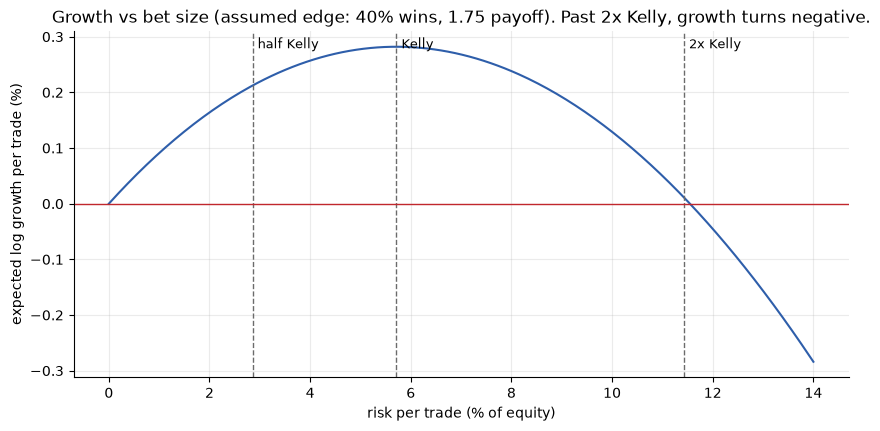

In [15]:
# The catch: Kelly needs the TRUE edge, but a backtest only gives an estimate. Bootstrap the toy set and recompute Kelly each time.
R_toy = (toy.pnl / toy.risk_amount).to_numpy()
boot = np.random.default_rng(7).choice(R_toy, (10_000, len(R_toy)))
var = boot.var(axis=1); ok = var > 0                                           # a resample of ten identical trades has no variance
k_est = boot.mean(axis=1)[ok] / var[ok]                                         # small-edge approximation: mean R / variance of R
lo, med, hi = np.percentile(k_est, [5, 50, 95])
print(f"Kelly estimated from the 10 toy trades: median {med:.1%}, 90% of resamples between {lo:.1%} and {hi:.1%}; negative in {(k_est < 0).mean():.0%} of resamples")
assert lo < 0 < hi                                                               # ten trades cannot even say whether the edge is positive

fig, ax = plt.subplots(); f = np.linspace(0.0, 0.14, 300); ax.plot(f * 100, growth_per_trade(f) * 100, color=PALETTE["equity"])
for m, lab in [(0.5, "half Kelly"), (1, "Kelly"), (2, "2x Kelly")]:
    ax.axvline(m * k * 100, color=PALETTE["neutral"], ls="--", lw=1); ax.text(m * k * 100 + 0.1, ax.get_ylim()[1] * 0.9, lab, fontsize=9)
ax.axhline(0, color=PALETTE["loss"], lw=1); ax.set_xlabel("risk per trade (% of equity)"); ax.set_ylabel("expected log growth per trade (%)")
ax.set_title("Growth vs bet size (assumed edge: 40% wins, 1.75 payoff). Past 2x Kelly, growth turns negative."); plt.show()

---
# Part 4 — Returns and risk-adjusted ratios

- **Total return** = final ÷ initial − 1
- **Annualised return (CAGR)** = (final ÷ initial)^(1 ÷ years) − 1. Not meaningful on very short tests, so under a quarter of a year we fall back to total return (as the breakout notebook does).
- **Volatility** = standard deviation of daily returns × √252
- **Sharpe** = √252 × mean(excess return) ÷ std(excess return), with excess = daily return − risk-free (2%/yr ÷ 252)
- **Sortino** = like Sharpe, but divides by the *downside* deviation: the root-mean-square of the negative excess returns over **all** days
- **Calmar** = annualised return ÷ max drawdown

**Conventions used (same as the breakout notebook):** weekday daily returns only, flat days *included*, `std` with `ddof=0`, 2% risk-free.

### Hand check on a four-day return series
Returns `[+2%, −1%, +2%, −1%]`, risk-free = 0: mean = 0.5%, std = 1.5% → daily Sharpe 0.3333 → × √252 = **5.2915**.
Downside deviation = √((0 + 0.01² + 0 + 0.01²) ÷ 4) = 0.7071% → daily Sortino 0.7071 → × √252 = **11.2250**.

In [16]:
def sharpe(r, rf=0.02, periods=252):
    ex = np.asarray(r) - rf / periods; sd = ex.std()
    return np.sqrt(periods) * ex.mean() / sd if sd > 1e-12 else np.nan      # zero volatility: the ratio is undefined, not zero

def sortino(r, rf=0.02, periods=252):
    ex = np.asarray(r) - rf / periods; down = np.sqrt(np.mean(np.minimum(ex, 0) ** 2))
    return np.sqrt(periods) * ex.mean() / down if down > 0 else (np.inf if ex.mean() > 0 else 0.0)

def daily_returns(equity: pd.Series) -> pd.Series:
    d = equity.resample("D").last().ffill()
    return d[d.index.dayofweek < 5].pct_change().dropna()

def return_metrics(equity: pd.Series, ic: float, max_dd_pct: float, rf=0.02) -> dict:
    final, total = equity.iloc[-1], equity.iloc[-1] / ic - 1
    years = (equity.index[-1] - equity.index[0]).days / 365.25
    cagr = (final / ic) ** (1 / years) - 1 if years >= 0.25 else total
    r = daily_returns(equity)
    return {"total_return": total, "cagr": cagr, "volatility": r.std(ddof=0) * np.sqrt(252),
            "sharpe": sharpe(r, rf), "sortino": sortino(r, rf),
            "calmar": cagr / max_dd_pct if max_dd_pct else np.inf}

hand = [0.02, -0.01, 0.02, -0.01]
assert np.isclose(sharpe(hand, rf=0), np.sqrt(252) / 3)
assert np.isclose(sortino(hand, rf=0), np.sqrt(252) * 0.005 / np.sqrt(0.00005))
assert np.isnan(sharpe([0.0, 0.0, 0.0], rf=0))                 # a strategy that never moves has no Sharpe ratio
print(f"Sharpe {sharpe(hand, rf=0):.4f} | Sortino {sortino(hand, rf=0):.4f}")

pd.Series(return_metrics(toy_equity, 10_000, dd_mtm["max_dd_pct"]), name="toy (30 days: CAGR falls back to total return)").to_frame()

Sharpe 5.2915 | Sortino 11.2250


,toy (30 days: CAGR falls back to total return)
total_return,0.0100
cagr,0.0100
volatility,0.1348
sharpe,0.5600
sortino,1.0834
calmar,0.3172


### 4.1 Return tables: year by year and month by month
A single total return hides *when* the money was made. Always look at the table.

In [17]:
def period_returns(equity: pd.Series, ic: float, freq: str) -> pd.Series:
    end = equity.resample(freq).last()
    return end.pct_change().fillna(end.iloc[0] / ic - 1)          # first period measured against the starting capital

### 4.2 Where Sharpe misleads: flat days

If a strategy is only in the market on a few days, and you drop the flat days from the return series, Sharpe is inflated by roughly `1 ÷ √(fraction of days in the market)`. The breakout notebook had exactly this bug (it reported 1.9 where the right answer was about 0.2) and fixed it by keeping flat days. The demo below uses a **synthetic** return series that is active on about 9% of days (226 of 2,520).

In [18]:
rng = np.random.default_rng(3)
n_days, f_active = 2520, 0.09
active = np.zeros(n_days, bool); active[rng.choice(n_days, int(f_active * n_days), replace=False)] = True
x = rng.normal(0, 0.01, active.sum()); x = x - x.mean() + 0.0004             # SYNTHETIC: active-day mean fixed at +0.04%
r_all = np.zeros(n_days); r_all[active] = x

sh_all, sh_active_only = sharpe(r_all, rf=0), sharpe(r_all[active], rf=0)
print(f"Sharpe, flat days kept: {sh_all:.2f} | flat days dropped: {sh_active_only:.2f} | ratio {sh_active_only / sh_all:.2f} "
      f"(theory: 1/sqrt({active.mean():.3f}) = {1 / np.sqrt(active.mean()):.2f})")
assert abs(sh_active_only / sh_all - 1 / np.sqrt(active.mean())) < 0.4

Sharpe, flat days kept: 0.19 | flat days dropped: 0.64 | ratio 3.34 (theory: 1/sqrt(0.090) = 3.34)


**Other ways each ratio misleads**
- **Sharpe** is **undefined** when volatility is zero (a strategy that never trades), is **blind to leverage** (see 4.5), and treats upside and downside swings as equally bad, and a strategy that sells rare disasters for small steady gains can show a great Sharpe right up to the disaster.
- **Sortino** fixes the first problem but is just as blind to a short history.
- **Calmar** depends on **one** drawdown, the worst one. A different start date can change it a lot.
- **All of them** are point estimates from one backtest. Part 5 asks how much luck is in them.

### 4.3 Log vs simple returns, and the annualisation factor

- **Simple return** `r = P1/P0 − 1`. Averages of simple returns **overstate** growth when returns are volatile.
- **Log return** `ln(1 + r)`. Log returns **add up**: `exp(sum of log returns) − 1` is exactly the total return.
- So the **arithmetic annualised mean** (`mean(r) × periods`) is always at or above the **true growth rate** (`mean log return × periods`, whose `exp − 1` is the **CAGR**). The gap is about `½ σ²` per period: the *volatility drag*. It grows with volatility, and leverage multiplies volatility.

The **annualisation factor** also matters: Sharpe and volatility scale with `√periods`. Equities use 252. Forex data that includes Sunday bars can have far more bars a year, so count them instead of assuming.

In [19]:
rng = np.random.default_rng(11)
mu_d, sd_d, n = 0.0004, 0.01, 2520                          # SYNTHETIC daily simple returns: about 10% a year at 16% volatility
r = rng.normal(0, sd_d, n); r = r - r.mean() + mu_d          # fix the sample mean so the demo is clean
equity_s = 10_000 * np.cumprod(1 + r)
assert np.isclose(np.expm1(np.log1p(r).sum()), equity_s[-1] / 10_000 - 1)           # log returns ADD UP to the same total return

arith_annual = r.mean() * 252                                  # what "mean return x 252" gives
log_annual = np.log1p(r).mean() * 252                          # mean LOG return x 252: the true annual growth rate
cagr_s = (equity_s[-1] / 10_000) ** (1 / (n / 252)) - 1
drag_theory = 252 * r.var() / 2                                # volatility drag: about half the variance, annualised
print(f"SYNTHETIC | arithmetic annual mean {arith_annual:.2%} | log growth {log_annual:.2%} | CAGR {cagr_s:.2%} "
      f"| drag {arith_annual - log_annual:.2%} (theory: 252 x variance / 2 = {drag_theory:.2%})")
assert np.isclose(np.expm1(log_annual), cagr_s)                 # CAGR is exactly exp(mean log return x periods) - 1
assert arith_annual > log_annual and abs((arith_annual - log_annual) - drag_theory) < 0.002

def bars_per_year(index: pd.DatetimeIndex) -> float:
    return (len(index) - 1) / ((index[-1] - index[0]).days / 365.25)
assert 258 < bars_per_year(pd.bdate_range("2010-01-01", "2019-12-31")) < 263          # weekday-only candles: about 261
assert 363 < bars_per_year(pd.date_range("2010-01-01", "2019-12-31")) < 367           # candles on all 7 days: 365
for bpy in (261, 291):
    print(f"if the data really has {bpy} bars a year, using 252 misstates Sharpe and volatility by a factor of {np.sqrt(bpy / 252):.3f}")

SYNTHETIC | arithmetic annual mean 10.08% | log growth 8.81% | CAGR 9.21% | drag 1.27% (theory: 252 x variance / 2 = 1.27%)
if the data really has 261 bars a year, using 252 misstates Sharpe and volatility by a factor of 1.018
if the data really has 291 bars a year, using 252 misstates Sharpe and volatility by a factor of 1.075


### 4.4 Downside deviation: the target, and the classic bug

Downside deviation measures only the bad days, against a **minimum acceptable return** (the *target*, often 0, or the risk-free rate as the Sortino above uses). The recipe: subtract the target, **replace positive excess returns with zero** (do not delete them), square, take the **mean over ALL days**, then the square root. Deleting the positive days shrinks the denominator of the mean and **overstates** the downside, which **understates** Sortino.

In [20]:
def downside_deviation(r, mar=0.0, periods=1):
    ex = np.minimum(np.asarray(r, float) - mar, 0.0)                    # positives become ZERO but stay in the average
    return np.sqrt(np.mean(ex ** 2)) * np.sqrt(periods)

def downside_deviation_WRONG(r, mar=0.0):                               # the common bug, shown so you can recognise it
    ex = np.asarray(r, float) - mar
    return np.sqrt(np.mean(ex[ex < 0] ** 2))                            # positive days deleted: fewer observations in the mean

assert np.isclose(downside_deviation(hand), np.sqrt(0.00005))           # 0.7071%: (0 + 1% + 0 + 1%)/4 -> sqrt(0.005%)
assert np.isclose(downside_deviation_WRONG(hand), 0.01)                 # 1.0000%: wrong, too big
sortino_ok = np.sqrt(252) * 0.005 / downside_deviation(hand); sortino_bad = np.sqrt(252) * 0.005 / downside_deviation_WRONG(hand)
assert np.isclose(sortino_ok, sortino(hand, rf=0))
assert np.isclose(downside_deviation(hand, mar=0.005), np.sqrt(1.125e-4))   # target +0.5%/day: excess [+1.5, -1.5, +1.5, -1.5]% -> sqrt((2.25+2.25)/4 %)
print(f"correct downside deviation {downside_deviation(hand):.4%} -> Sortino {sortino_ok:.4f} | "
      f"positives deleted {downside_deviation_WRONG(hand):.4%} -> Sortino {sortino_bad:.4f}")
print(f"the target is a choice: downside deviation with target 0 = {downside_deviation(hand):.4%}, with target +0.5%/day = {downside_deviation(hand, mar=0.005):.4%}")
print(f"annualised (x sqrt 252): {downside_deviation(hand, periods=252):.4%}")

correct downside deviation 0.7071% -> Sortino 11.2250 | positives deleted 1.0000% -> Sortino 7.9373
the target is a choice: downside deviation with target 0 = 0.7071%, with target +0.5%/day = 1.0607%
annualised (x sqrt 252): 11.2250%


### 4.5 What leverage does to each number

Leverage `L` multiplies every daily simple return by `L`. Then:
- the **mean** and the **volatility** both scale by `L`, so the **Sharpe ratio on simple returns does not change at all**. Sharpe cannot see leverage.
- but **compounded growth** does: it peaks at the Kelly leverage, then falls (volatility drag grows with `L²`).
- and **drawdown** grows faster than linearly.

For daily simple returns the Kelly leverage is approximately `mean(r) ÷ variance(r)` (this is the formula you use on a return series; the `p − q/b` form in 3.2 is for discrete win/loss trades).

SYNTHETIC | Kelly leverage = mean/variance = 3.97 | growth peaks at 4.0x | Sharpe at every leverage: 0.633


,mean_simple_x252,volatility,sharpe,sharpe_on_log_returns,mean_log_x252,max_drawdown
leverage,,,,,,
1.0000,0.1008,0.1593,0.6328,0.5531,0.0881,0.2457
2.0000,0.2016,0.3186,0.6328,0.4733,0.1508,0.4483
3.0000,0.3024,0.4779,0.6328,0.3933,0.1881,0.6099
4.0000,0.4032,0.6372,0.6328,0.3132,0.1998,0.7513
5.0000,0.5040,0.7964,0.6328,0.2330,0.1860,0.8597
6.0000,0.6048,0.9557,0.6328,0.1525,0.1463,0.9278
8.0000,0.8064,1.2743,0.6328,-0.0089,-0.0115,0.9855


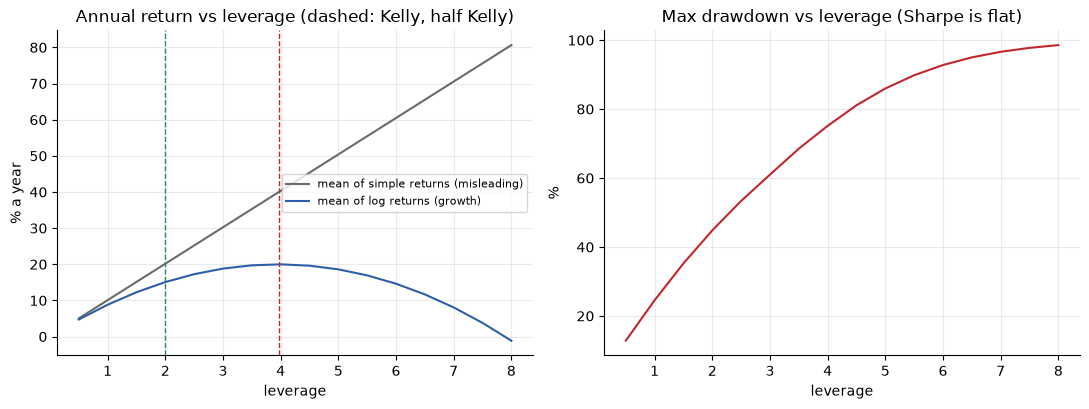

In [21]:
Ls = np.arange(0.5, 8.01, 0.5); rows = []
for L in Ls:
    lr = np.maximum(L * r, -0.9999)                                     # a day cannot lose more than 100%
    path = np.cumprod(1 + lr)
    rows.append({"leverage": L, "mean_simple_x252": lr.mean() * 252, "volatility": lr.std() * np.sqrt(252), "sharpe": sharpe(lr, rf=0), "sharpe_on_log_returns": sharpe(np.log1p(lr), rf=0),
                 "mean_log_x252": np.log1p(lr).mean() * 252, "max_drawdown": ((np.maximum.accumulate(path) - path) / np.maximum.accumulate(path)).max()})
lev = pd.DataFrame(rows).set_index("leverage")
kelly_lev = r.mean() / r.var()                                            # mean of SIMPLE returns / variance of SIMPLE returns
assert np.ptp(lev["sharpe"]) < 1e-9                                       # Sharpe is identical at every leverage
assert lev["sharpe_on_log_returns"].is_monotonic_decreasing                # computed on LOG returns, Sharpe falls with leverage: a different question
assert lev["mean_simple_x252"].is_monotonic_increasing                    # the arithmetic mean just keeps rising: it is misleading
assert abs(lev["mean_log_x252"].idxmax() - kelly_lev) <= 0.5              # growth peaks at the Kelly leverage (within one grid step)
print(f"SYNTHETIC | Kelly leverage = mean/variance = {kelly_lev:.2f} | growth peaks at {lev['mean_log_x252'].idxmax():.1f}x | Sharpe at every leverage: {lev['sharpe'].iloc[0]:.3f}")
display(lev.loc[[1, 2, 3, 4, 5, 6, 8]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(lev.index, lev["mean_simple_x252"] * 100, color=PALETTE["neutral"], label="mean of simple returns (misleading)")
axes[0].plot(lev.index, lev["mean_log_x252"] * 100, color=PALETTE["equity"], label="mean of log returns (growth)")
axes[0].axvline(kelly_lev, color=PALETTE["loss"], ls="--", lw=1); axes[0].axvline(kelly_lev / 2, color=PALETTE["win"], ls="--", lw=1)
axes[0].set_title("Annual return vs leverage (dashed: Kelly, half Kelly)"); axes[0].set_xlabel("leverage"); axes[0].set_ylabel("% a year"); axes[0].legend(fontsize=8)
axes[1].plot(lev.index, lev["max_drawdown"] * 100, color=PALETTE["loss"]); axes[1].set_title("Max drawdown vs leverage (Sharpe is flat)"); axes[1].set_xlabel("leverage"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

---
# Part 5 — Is the result luck?

A backtest gives you **one** history. Statistics asks: how different could the numbers have been by chance?

### 5.1 The sample-size problem
How often would a system with **zero edge** (a fair coin: +1R or −1R, 50/50) show a profit factor of 1.23 or better? Profit factor for ±1R trades is `wins ÷ losses`, so with `n` trades you need `k ≥ 1.23·n ÷ 2.23` wins. This is exact (binomial), then checked by simulation.

In [22]:
def p_pf_at_least(pf: float, n: int) -> float:
    """P(profit factor >= pf) for a zero-edge +/-1R system over n trades."""
    return binom.sf(int(np.ceil(pf * n / (1 + pf))) - 1, n, 0.5)

# check the exact formula against a brute-force simulation
rng = np.random.default_rng(0)
k = rng.binomial(36, 0.5, 400_000)
sim = np.mean(k / np.maximum(36 - k, 1e-9) >= 1.23)
assert abs(p_pf_at_least(1.23, 36) - sim) < 0.005

pf_table = pd.DataFrame({"trades": [10, 36, 100, 400, 1600]})
pf_table["P(PF >= 1.23 | zero edge)"] = [p_pf_at_least(1.23, n) for n in pf_table.trades]
pf_table["P(PF >= 1.50 | zero edge)"] = [p_pf_at_least(1.50, n) for n in pf_table.trades]
pf_table

,trades,P(PF >= 1.23 | zero edge),P(PF >= 1.50 | zero edge)
0,10,0.3770,0.3770
1,36,0.3089,0.1215
2,100,0.1356,0.0284
3,400,0.0201,0.0000
4,1600,0.0000,0.0000


### 5.2 The bootstrap confidence interval on expectancy
Resample your own trades **with replacement**, many times; each resample gives an average R per trade. The 2.5th and 97.5th percentiles of those averages form a 95% interval. If it **straddles zero**, the result cannot be told apart from no edge.

**Caveat:** the bootstrap treats trades as independent. Trades on correlated pairs are not, so the true interval is **wider** than the one you compute.

In [23]:
def bootstrap_expectancy(R, n_boot=10_000, seed=7) -> dict:
    R = np.asarray(R, float)
    means = np.random.default_rng(seed).choice(R, (n_boot, len(R))).mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return {"n": len(R), "mean_R": R.mean(), "ci_lo": lo, "ci_hi": hi, "p_mean_gt_0": (means > 0).mean(), "_means": means}

# check: with identical trades there is nothing to resample, so the interval collapses to a point
b = bootstrap_expectancy(np.ones(20)); assert b["ci_lo"] == b["ci_hi"] == 1.0 and b["p_mean_gt_0"] == 1.0

# the toy set: 10 trades is far too few
b_toy = bootstrap_expectancy(toy.pnl / toy.risk_amount)
print(f"toy set: {b_toy['mean_R']:+.2f}R per trade | 95% CI [{b_toy['ci_lo']:+.2f}, {b_toy['ci_hi']:+.2f}] | straddles zero: {b_toy['ci_lo'] <= 0 <= b_toy['ci_hi']}")

toy set: +0.10R per trade | 95% CI [-0.70, +1.00] | straddles zero: True


### 5.3 Monte Carlo: resample the whole account
Resample trades (in R) with replacement, compound them at your fixed risk %, and count how often the account **ends below the start** and how often it **touches −50%**. This answers *"if the next N trades come from this same distribution…"*. It is not a forecast.

In [24]:
def resample_equity(R, ic, risk_pct, n_sims=2_000, seed=7) -> dict:
    paths = ic * np.cumprod(1 + risk_pct * np.random.default_rng(seed).choice(np.asarray(R, float), (n_sims, len(R))), axis=1)
    return {"p_end_below_start": (paths[:, -1] < ic).mean(), "p_touch_minus_50": (paths.min(axis=1) <= 0.5 * ic).mean()}

# check: all-winning trades can never end below the start or halve the account
assert resample_equity(np.full(50, 1.0), 10_000, 0.01) == {"p_end_below_start": 0.0, "p_touch_minus_50": 0.0}

### 5.4 The demo log
For the next two parts we need more than 10 trades. `make_demo_trades` generates **SYNTHETIC** trades (seeded, 300 trades over ~6 years, 38% win rate, wins of 1.5R–2.5R, losses of −1R, 1% risk compounding). It exists only to demonstrate the statistics. **It is not a real strategy and its results mean nothing.**

SYNTHETIC demo | 300 trades | +0.198R per trade | 95% CI [+0.033, +0.360] | P(mean>0) 99.1%
SYNTHETIC demo | P(end below start) 1.2% | P(touch -50%) 0.0%


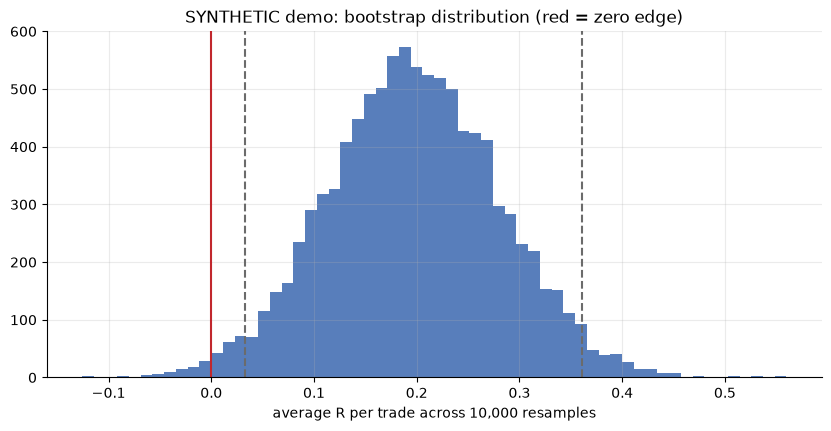

In [25]:
def make_demo_trades(n=300, seed=11, ic=10_000, risk_pct=0.01, p_win=0.38) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    R = np.where(rng.random(n) < p_win, rng.uniform(1.5, 2.5, n), -1.0)
    bal_before = ic * np.r_[1, np.cumprod(1 + risk_pct * R)][:-1]
    entry = pd.Timestamp("2018-01-01") + pd.to_timedelta(7 * np.arange(n) + rng.integers(0, 3, n), "D")
    return pd.DataFrame({"symbol": rng.choice(["EURUSD", "GBPUSD", "USDJPY"], n), "entry_date": entry,
                         "exit_date": entry + pd.to_timedelta(rng.integers(1, 6, n), "D"),
                         "pnl": R * bal_before * risk_pct, "risk_amount": bal_before * risk_pct})

demo = make_demo_trades()
demo_equity = pd.Series(closed_equity(demo, 10_000), index=[demo.entry_date.iloc[0], *demo.exit_date]).resample("D").last().ffill()
R_demo = (demo.pnl / demo.risk_amount).to_numpy()

boot = bootstrap_expectancy(R_demo); mc = resample_equity(R_demo, 10_000, 0.01)
print(f"SYNTHETIC demo | {boot['n']} trades | {boot['mean_R']:+.3f}R per trade | 95% CI [{boot['ci_lo']:+.3f}, {boot['ci_hi']:+.3f}] | P(mean>0) {boot['p_mean_gt_0']:.1%}")
print(f"SYNTHETIC demo | P(end below start) {mc['p_end_below_start']:.1%} | P(touch -50%) {mc['p_touch_minus_50']:.1%}")

fig, ax = plt.subplots()
ax.hist(boot["_means"], bins=60, color=PALETTE["equity"], alpha=0.8)
for x in (boot["ci_lo"], boot["ci_hi"]): ax.axvline(x, color=PALETTE["neutral"], ls="--")
ax.axvline(0, color=PALETTE["loss"]); ax.set(xlabel="average R per trade across 10,000 resamples", title="SYNTHETIC demo: bootstrap distribution (red = zero edge)")
plt.show()

---
# Part 6 — Is it robust? + the final checklist

A result is robust if it survives **changes you didn't plan for**: more cost, a different slice of time, a different instrument, a different parameter.

### 6.1 Cost stress
Subtract extra cost from every trade and see where the edge disappears. The **breakeven extra cost per trade, in R, equals the expectancy in R**: that is exactly how much cost the strategy can absorb.

In [26]:
def cost_stress(trades: pd.DataFrame, extra_R=(0, 0.05, 0.10, 0.15, 0.20)) -> pd.DataFrame:
    R = (trades.pnl / trades.risk_amount).to_numpy(); rows = []
    for c in extra_R:
        x = R - c; loss = -x[x <= 0].sum()
        rows.append({"extra_cost_R": c, "expectancy_R": x.mean(), "profit_factor": x[x > 0].sum() / loss if loss else np.inf})
    return pd.DataFrame(rows)

cs = cost_stress(toy, extra_R=(0, 0.05, 0.10))
assert np.isclose(cs.loc[2, "expectancy_R"], 0) and np.isclose(cs.loc[2, "profit_factor"], 1)      # toy: 0.10R is the breakeven cost
cost_stress(toy)

,extra_cost_R,expectancy_R,profit_factor
0,0.0000,0.1000,1.1667
1,0.0500,0.0500,1.0794
2,0.1000,-0.0000,1.0000
3,0.1500,-0.0500,0.9275
4,0.2000,-0.1000,0.8611


### 6.2 Break the result into pieces
Per instrument, per year, per time slice. A strategy that only works on one pair, in one stretch of years, is a coincidence until proven otherwise.

In [27]:
def breakdown(trades: pd.DataFrame, key) -> pd.DataFrame:
    t = trades.assign(R=trades.pnl / trades.risk_amount, win=trades.pnl > 0)
    return t.groupby(key).agg(trades=("pnl", "size"), win_rate=("win", "mean"), net_pnl=("pnl", "sum"), expectancy_R=("R", "mean"))

def fold_test(trades: pd.DataFrame, n_folds=6) -> pd.DataFrame:
    edges = pd.date_range(trades.entry_date.min(), trades.entry_date.max(), periods=n_folds + 1)   # equal slices of CALENDAR time
    return breakdown(trades, pd.cut(trades.entry_date, edges, include_lowest=True, labels=range(1, n_folds + 1)).rename("fold"))

# checks on the toy set (EURUSD = trades 1,3,5,7,9 ; GBPUSD = 2,4,6,8,10)
bd = breakdown(toy, "symbol")
assert np.isclose(bd.loc["EURUSD", "net_pnl"], 150 - 100 - 100 - 100 + 250) and np.isclose(bd.loc["GBPUSD", "net_pnl"], -100 + 200 + 100 - 100 - 100)
assert fold_test(toy, 2).trades.sum() == 10
bd

,trades,win_rate,net_pnl,expectancy_R
symbol,,,,
EURUSD,5,0.4000,100,0.2000
GBPUSD,5,0.4000,0,0.0000


In [28]:
print("SYNTHETIC demo log, by instrument:");  display(breakdown(demo, "symbol"))
print("SYNTHETIC demo log, by year:");        display(breakdown(demo, demo.entry_date.dt.year.rename("year")))
print("SYNTHETIC demo log, six equal slices of calendar time:"); display(fold_test(demo))

SYNTHETIC demo log, by instrument:


,trades,win_rate,net_pnl,expectancy_R
symbol,,,,
EURUSD,101,0.4059,"2,597.7474",0.1838
GBPUSD,104,0.4615,"4,881.7092",0.3667
USDJPY,95,0.3368,64.9229,0.0293


SYNTHETIC demo log, by year:


,trades,win_rate,net_pnl,expectancy_R
year,,,,
2018,53,0.4528,"1,746.0555",0.3147
2019,52,0.4615,"2,347.6224",0.3620
2020,52,0.5000,"4,334.8668",0.5288
2021,52,0.2885,"-1,531.8361",-0.1580
2022,52,0.4038,"1,923.0185",0.2186
2023,39,0.2821,"-1,275.3475",-0.1710


SYNTHETIC demo log, six equal slices of calendar time:


,trades,win_rate,net_pnl,expectancy_R
fold,,,,
1,51,0.4510,"1,639.0834",0.3086
2,49,0.4898,"2,734.2772",0.4425
3,50,0.4800,"3,717.9377",0.4730
4,50,0.3000,"-1,147.4248",-0.1219
5,50,0.4000,"1,699.1565",0.2022
6,50,0.3000,"-1,098.6504",-0.1121


### 6.3 Overfitting, out-of-sample and walk-forward

**Overfitting:** if you try enough parameter values, one of them will look good on any data, even pure noise. **Out-of-sample (OOS)** testing keeps data the optimisation never saw. **Walk-forward** repeats this: optimise on a training window, trade the next window, slide forward, and stitch the out-of-sample pieces together.

The demo uses **SYNTHETIC random-walk prices** (no edge by construction) and a simple Donchian-breakout rule with 20 candidate lookbacks. For each of 200 random walks we pick the lookback with the best in-sample Sharpe and measure what it does on the second half.

      sharpe_in_sample  sharpe_out_of_sample
mean            0.5051                0.0095
50%             0.4914                0.0234


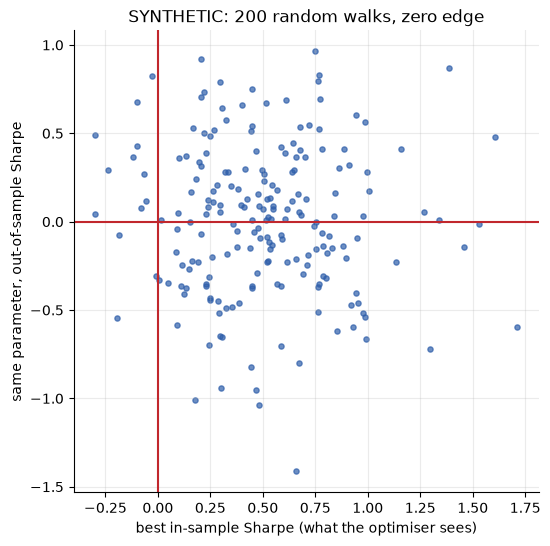

In [29]:
GRID = range(10, 201, 10)

def random_walk(seed, n=2520, vol=0.01) -> pd.Series:          # SYNTHETIC: no edge by construction
    return pd.Series(100 * np.exp(np.cumsum(np.random.default_rng(seed).normal(0, vol, n))), index=pd.bdate_range("2014-01-01", periods=n))

def donchian_returns(close: pd.Series, n: int) -> pd.Series:
    hi, lo = close.rolling(n).max().shift(), close.rolling(n).min().shift()
    pos = pd.Series(np.select([close > hi, close < lo], [1.0, -1.0], np.nan), index=close.index).ffill().fillna(0)
    return pos.shift().fillna(0) * close.pct_change().fillna(0)              # position decided on yesterday's data

def best_in_sample(seed):
    c = random_walk(seed); half = len(c) // 2
    r = {n: donchian_returns(c, n) for n in GRID}
    best = max(GRID, key=lambda n: sharpe(r[n].iloc[:half], rf=0))
    return best, sharpe(r[best].iloc[:half], rf=0), sharpe(r[best].iloc[half:], rf=0)

# sanity checks on the rule itself: a steadily rising price must be long (return > 0), a falling one short (return > 0)
up, down = pd.Series(np.linspace(100, 200, 300)), pd.Series(np.linspace(200, 100, 300))
assert donchian_returns(up, 20).sum() > 0 and donchian_returns(down, 20).sum() > 0

res = pd.DataFrame([best_in_sample(s) for s in range(200)], columns=["lookback", "sharpe_in_sample", "sharpe_out_of_sample"])
print(res[["sharpe_in_sample", "sharpe_out_of_sample"]].describe().loc[["mean", "50%"]])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(res.sharpe_in_sample, res.sharpe_out_of_sample, s=14, color=PALETTE["equity"], alpha=0.7)
ax.axhline(0, color=PALETTE["loss"]); ax.axvline(0, color=PALETTE["loss"])
ax.set(xlabel="best in-sample Sharpe (what the optimiser sees)", ylabel="same parameter, out-of-sample Sharpe",
       title="SYNTHETIC: 200 random walks, zero edge")
plt.show()

In [30]:
def walk_forward(close: pd.Series, train_years=3, test_years=1):
    r = {n: donchian_returns(close, n) for n in GRID}
    seg = lambda s, a, b: s[(s.index >= a) & (s.index < b)]
    start, oos, picks = close.index[0], [], []
    while (test_end := start + pd.DateOffset(years=train_years + test_years)) <= close.index[-1]:
        train_end = start + pd.DateOffset(years=train_years)
        best = max(GRID, key=lambda n: sharpe(seg(r[n], start, train_end), rf=0))
        oos.append(seg(r[best], train_end, test_end)); picks.append({"train_start": start.date(), "chosen_lookback": best})
        start += pd.DateOffset(years=test_years)
    return pd.concat(oos), pd.DataFrame(picks)

oos_returns, picks = walk_forward(random_walk(0))
assert len(picks) == 6                                         # 2,520 business days from 2014-01-01 fit six 3+1-year windows
print(f"SYNTHETIC walk-forward on one random walk: stitched out-of-sample Sharpe {sharpe(oos_returns, rf=0):+.2f}")
picks

SYNTHETIC walk-forward on one random walk: stitched out-of-sample Sharpe +0.29


,train_start,chosen_lookback
0,2014-01-01,180
1,2015-01-01,180
2,2016-01-01,180
3,2017-01-01,20
4,2018-01-01,20
5,2019-01-01,40


In [31]:
# one random walk proves little either way, so repeat the whole walk-forward on 60 different random walks
wf_sharpes = np.array([sharpe(walk_forward(random_walk(s))[0], rf=0) for s in range(60)])
print(f"SYNTHETIC: stitched walk-forward out-of-sample Sharpe over 60 random walks | mean {wf_sharpes.mean():+.2f} | share positive {np.mean(wf_sharpes > 0):.0%}")

SYNTHETIC: stitched walk-forward out-of-sample Sharpe over 60 random walks | mean +0.06 | share positive 57%


### 6.4 The whole report in one function
Everything above, assembled. `backtest_report` takes a trade log, an equity curve and the settings, and returns every section. `red_flags` turns the numbers into plain warnings.

**The thresholds in `red_flags` are rules of thumb, not laws** (100 trades, half the years profitable, a 25% gap between the two drawdowns). Change them if you disagree.

In [32]:
def red_flags(tm, luck, by_year, dd_closed, dd_mtm, min_trades=100, min_profitable_years=0.5, dd_gap=1.25) -> list:
    f = []
    if tm["trade_count"] < min_trades:           f.append(f"Small sample: {tm['trade_count']} trades (rule of thumb: at least {min_trades})")
    if luck["ci_lo"] <= 0 <= luck["ci_hi"]:      f.append("Expectancy interval includes zero: cannot be told apart from no edge")
    if tm["profit_factor"] < 1:                  f.append("Net loser: profit factor below 1")
    if tm["win_rate"] < tm["breakeven_win_rate"]: f.append("Win rate is below the breakeven rate for its own payoff ratio")
    if (by_year > 0).mean() < min_profitable_years: f.append("Fewer than half the years were profitable")
    if dd_mtm["max_dd_pct"] > dd_gap * dd_closed["max_dd_pct"]: f.append("Mark-to-market drawdown is much worse than closed-trade drawdown")
    return f

def backtest_report(trades: pd.DataFrame, equity: pd.Series, settings: Settings = Settings(), n_boot=10_000) -> dict:
    ic = settings.initial_capital
    tm = trade_metrics(trades)
    dd_c, dd_m = drawdown_stats(closed_equity(trades, ic)), drawdown_stats(equity.to_numpy())
    R = (trades.pnl / trades.risk_amount).to_numpy()
    luck = {**bootstrap_expectancy(R, n_boot), **resample_equity(R, ic, settings.risk_pct)}; luck.pop("_means")
    by_year = trades.groupby(trades.entry_date.dt.year).pnl.sum()
    risk = {"max_dd_closed_pct": dd_c["max_dd_pct"], "max_dd_mtm_pct": dd_m["max_dd_pct"], "max_dd_mtm_usd": dd_m["max_dd_usd"],
            "longest_underwater_bars": dd_m["longest_underwater_bars"], "max_losing_streak": max_streak(trades.pnl, False),
            "exposure": exposure(trades, equity.index),
            "recovery_factor": recovery_factor(equity.iloc[-1] - ic, dd_m["max_dd_usd"])}
    return {"assumptions": assumptions_table(settings), "trade": tm, "risk": risk,
            "returns": return_metrics(equity, ic, dd_m["max_dd_pct"]), "luck": luck, "by_year": by_year,
            "flags": red_flags(tm, luck, by_year, dd_c, dd_m)}

def print_report(rep: dict, title="Backtest report") -> None:
    print(f"{'=' * 12} {title} {'=' * 12}")
    for name in ("assumptions", "trade", "risk", "returns", "luck"):
        print(f"\n-- {name} --"); print(rep[name] if name == "assumptions" else pd.Series(rep[name]).to_string())
    print("\n-- net P&L by year --"); print(rep["by_year"].round(2).to_string())
    print("\n-- red flags --"); print("\n".join(f"  ! {f}" for f in rep["flags"]) or "  none triggered")

# --- toy set: must reproduce every hand-calculated number
rep_toy = backtest_report(toy, toy_equity, Settings(timeframe="D", window="30 business days (toy)"))
assert np.isclose(rep_toy["trade"]["profit_factor"], 700 / 600) and np.isclose(rep_toy["risk"]["max_dd_mtm_pct"], 320 / 10_150)
assert rep_toy["risk"]["max_losing_streak"] == 2 and np.isclose(rep_toy["risk"]["exposure"], 20 / 30)
print_report(rep_toy, "TOY SET (10 trades)")

============ TOY SET (10 trades) ============

-- assumptions --
                                     value
initial_capital                      10000
risk_pct                            0.0100
spread_pips                         2.0000
slippage_pips                       0.5000
commission_per_lot                  2.0000
timeframe                                D
window              30 business days (toy)
fill_basis                             mid
max_open_positions                       1

-- trade --
trade_count                        10
win_rate                       0.4000
avg_win                      175.0000
avg_loss                     100.0000
payoff_ratio                   1.7500
profit_factor                  1.1667
expectancy_usd                10.0000
expectancy_R                   0.1000
breakeven_win_rate             0.3636
largest_win                       250
largest_loss                     -100
avg_duration          2 days 19:12:00

-- risk --
max_dd_closed_pct       

In [33]:
print_report(backtest_report(demo, demo_equity, Settings(timeframe="D", window="2018-2023 (SYNTHETIC)")), "SYNTHETIC DEMO LOG (not a real strategy)")

============ SYNTHETIC DEMO LOG (not a real strategy) ============

-- assumptions --
                                    value
initial_capital                     10000
risk_pct                           0.0100
spread_pips                        2.0000
slippage_pips                      0.5000
commission_per_lot                 2.0000
timeframe                               D
window              2018-2023 (SYNTHETIC)
fill_basis                            mid
max_open_positions                      1

-- trade --
trade_count                       300
win_rate                       0.4033
avg_win                      302.9007
avg_loss                     162.6068
payoff_ratio                   1.8628
profit_factor                  1.2592
expectancy_usd                25.1479
expectancy_R                   0.1983
breakeven_win_rate             0.3493
largest_win                  456.9978
largest_loss                -195.9525
avg_duration          3 days 01:31:12

-- risk --
max_dd_closed

### 6.5 Run it on a real report: Strategy 8 from the breakout audit

**Step 1 — export the trade log** from the *Breakout Strategy Framework* notebook. In Section 10, with `ACTIVE_VARIANT` set to Strategy 8 (`8_control_breakout`) and the results cells run, add and run one cell:

```python
trades.to_csv("strategy8_trades.csv", index=False)
equity_curve.to_csv("strategy8_equity.csv", index=False)
```

**Step 2 — copy both CSVs next to this notebook** and run the cell below. It uses the same columns the engine writes (`entry_date`, `exit_date`, `pnl`, `risk_amount`, `symbol`; and `date`, `equity` for the curve).

Note: the breakout notebook's headline drawdown is the **closed-trade** one; this report shows both.

In [34]:
TRADES_CSV, EQUITY_CSV = Path("strategy8_trades.csv"), Path("strategy8_equity.csv")
if TRADES_CSV.exists() and EQUITY_CSV.exists():
    real_trades = pd.read_csv(TRADES_CSV, parse_dates=["entry_date", "exit_date"]).sort_values("exit_date")
    real_equity = pd.read_csv(EQUITY_CSV, parse_dates=["date"]).set_index("date")["equity"]
    print_report(backtest_report(real_trades, real_equity, Settings(timeframe="D", window="2006-10 to 2026-09")), "STRATEGY 8: REAL BREAKOUT-AUDIT TRADE LOG")
else:
    print("Strategy 8 files not found. Export them from the breakout notebook (step 1 above), put them next to this notebook, and re-run this cell.")

============ STRATEGY 8: REAL BREAKOUT-AUDIT TRADE LOG ============

-- assumptions --
                                 value
initial_capital                  10000
risk_pct                        0.0100
spread_pips                     2.0000
slippage_pips                   0.5000
commission_per_lot              2.0000
timeframe                            D
window              2006-10 to 2026-09
fill_basis                         mid
max_open_positions                   1

-- trade --
trade_count                               193
win_rate                               0.2694
avg_win                              118.8349
avg_loss                              68.0378
payoff_ratio                           1.7466
profit_factor                          0.6441
expectancy_usd                       -17.6887
expectancy_R                          -0.2087
breakeven_win_rate                     0.3641
largest_win                          625.6185
largest_loss                        -101.8684
avg_

---
## Series map: where each part shows up in the audits

| Part | Concept | Where you saw it |
|---|---|---|
| 1 | Costs vs stop size | Strategy 5 (stop smaller than the cost of entering); Strategy 1 (1:1 needs 50.2%) |
| 1 | Look at the settings first | Timeframe trap (Donchian-55 on hourly vs daily); Global Lock pair order |
| 2 | Win rate vs payoff, breakeven after costs | The 80% win-rate videos; Strategy 3's RSI exit |
| 3 | Closed vs mark-to-market drawdown | Section 10 vs the Section 11 equity chart |
| 4 | Flat days inflate Sharpe | A bug fixed in the breakout notebook |
| 5 | Sample size, bootstrap, Monte Carlo | Strategy 2 (36 trades); Strategy 8 (expectancy CI, 99.1% of resamples ended underwater) |
| 6 | Cost stress, per-pair and per-year, overfitting | Strategy 8 cost isolation; "3 of 7 pairs profitable"; the grid-search ratio in Strategy 7 |

| 3 | Drawdown date, duration in days, unfinished drawdown | Strategy 8: last high in 2008, no new high since (confirm with `drawdown_detail`) |
| 3 | Kelly fraction vs risk per trade | The toy edge: Kelly 5.7%, double Kelly = zero growth; 10-trade Kelly estimate is noise |
| 4 | Log vs simple returns, annualisation factor | Check bars per year before trusting Sharpe/volatility (261 vs 291) |
| 4 | Downside deviation target and the delete-the-positives bug | Sortino 11.23 vs 7.94 on the same four days |
| 4 | Leverage: Sharpe cannot see it | 4.5: Sharpe flat, growth peaks at Kelly, drawdown explodes |

*Not financial advice. This is a code and statistics notebook. Synthetic data is labelled as such and is for demonstration only.*